# Lesson 16 - Five classes: cargo and tanker together, judged per clip and per ship

Lessons 13-15 reached about 62 % balanced accuracy on six classes, one 5-second clip at a time. The goal now is
**75 %**. Two changes, both close to how the system would be used:

- **Cargo and tanker become one class** ("cargo + tanker"). They sound almost the same, and they cause most of the
  errors.
- **One answer per ship**, not per clip: the model's answers for all clips of a ship are averaged.

Everything else is lesson 13: the same folds and test ships, the same training weights, the same two feature sets
and models. Only the labels change.

| Section | Question |
|---|---|
| 1. Per clip and per ship | what the two scores mean, on a real ship |
| 2. Why cargo and tanker together | how alike they are |
| 3. Results | five classes against six, per clip and per ship |
| 4. What is still wrong | per class, and per ship by its number of clips |
| 5. What it means | |

```
python src/five_classes.py      # -> runs/five_classes/ (about 15 minutes, CPU; needs lesson 13's features)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import five_classes as F5
import six_classes as S
import six_classes_fewer as B
from paths import DATA_DIR

res =pd.DataFrame(json.loads((F5.OUT_DIR / "results.json").read_text())["results"])
preds = pd.read_parquet(F5.OUT_DIR / "predictions.parquet")
six = pd.DataFrame(json.loads((S.OUT_DIR / "results.json").read_text())["results"])
six_preds = pd.read_parquet(S.OUT_DIR / "predictions.parquet")
table = pd.read_parquet(DATA_DIR / "clips.parquet")
ships = S.ship_key(table)
P5, P6 = [f"p_{c}" for c in F5.CLASSES5], [f"p_{c}" for c in S.CLASSES6]
BEST = ("engineered", "gradient boosting")
pd.set_option("display.width", 160)

## 1. Per clip and per ship

- **Per clip:** every 5-second clip is judged on its own. The score is the share of clips named correctly,
  averaged over the classes so that every class counts the same (balanced accuracy).
- **Per ship:** the model's probabilities for all clips of the same ship in the test fold are averaged, and the
  class with the highest average is the ship's answer. The score is the share of ships named correctly, again with
  every class counting the same. Background has no ship; its clips are grouped by recording day.

Per ship is how the system would be used: one answer for each ship that passes the hydrophone. It helps most for
ships with many clips. How many clips does a ship have?

In [2]:
six_table = table[table.label.isin(S.CLASSES6)].assign(ship=ships)
per_ship = six_table.groupby(["label", "ship"]).size()
print(per_ship.groupby("label").agg(ships="size", clips="sum", mean="mean", median="median", most="max").round(1))

               ships  clips  mean  median  most
label                                          
background       802   3600   4.5     4.0     5
cargo           2522   3601   1.4     1.0     2
fishing          238   3601  15.1    15.0    16
pleasurecraft    406   3600   8.9     9.0     9
tanker           233   3601  15.5    15.0    16
tug              297   3601  12.1    12.0    13


A tanker from lesson 13's test folds (six classes, engineered features, gradient boosting): what each of its clips
was called, and the answer for the ship as a whole.

In [3]:
p6 = six_preds[(six_preds.features == BEST[0]) & (six_preds.model == BEST[1])].copy()
p6["ship"] = ships.iloc[p6.row].to_numpy()
p6["called"] = np.array(S.CLASSES6)[p6[P6].to_numpy().argmax(1)]
tankers = p6[p6.y == S.CLASSES6.index("tanker")].groupby("ship").agg(
    clips=("called", "size"), right=("called", lambda c: (c == "tanker").mean()),
    cargo=("called", lambda c: (c == "cargo").mean()), answer=("p_tanker", "mean"))
example = tankers[(tankers.clips >= 10) & tankers.right.between(0.4, 0.6) & (tankers.cargo >= 0.3)].index[0]
clips = p6[p6.ship == example]
print(f"{example}: {len(clips)} clips")
print(clips[["called", "p_tanker", "p_cargo"]].round(2).reset_index(drop=True).T.to_string())
avg = clips[P6].mean()
print(f"\nper clip: {(clips.called == 'tanker').sum()} of {len(clips)} clips right")
print("per ship: averaged probabilities " + ", ".join(f"{k[2:]} {v:.2f}" for k, v in avg.items()))
print(f"  -> the ship is called {avg.idxmax()[2:]}")

mmsi212656000: 15 clips
              0       1       2       3       4       5      6       7      8      9      10      11      12     13     14
called    tanker  tanker  tanker  tanker  tanker  tanker  cargo  tanker  cargo  cargo  cargo  tanker  tanker  cargo  cargo
p_tanker     0.7    0.56    0.65    0.76    0.68    0.53   0.34    0.61    0.3   0.22    0.2    0.69     0.5   0.45   0.17
p_cargo     0.22    0.44    0.34    0.23    0.28    0.46   0.65    0.37   0.58   0.77   0.68    0.28    0.49   0.48   0.83

per clip: 9 of 15 clips right
per ship: averaged probabilities background 0.00, cargo 0.47, fishing 0.01, pleasurecraft 0.01, tanker 0.49, tug 0.02
  -> the ship is called tanker


## 2. Why cargo and tanker together

In lesson 13 (six classes, engineered features, gradient boosting), cargo and tanker were mostly confused with each
other, rarely with anything else (rows: true class; %):

        background  cargo  fishing  pleasurecraft  tanker  tug
cargo            0     65        1              1      30    3
tanker           0     43        1              1      52    3


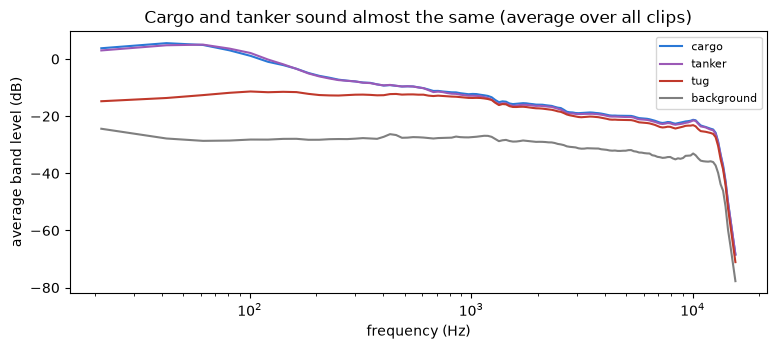

In [4]:
cm6 = confusion_matrix(p6.y, p6[P6].to_numpy().argmax(1), normalize="true")
print((100 * pd.DataFrame(cm6, index=S.CLASSES6, columns=S.CLASSES6)).round(0).astype(int).loc[["cargo", "tanker"]])

bands = pd.read_parquet(DATA_DIR / "features6_bands.parquet",
                        columns=["row"] + [f"band1_{g}_mean" for g in range(128)]).set_index("row")
centre = np.array([np.sqrt(lo * hi) for lo, hi in B.group_edges(1)])
level = bands.groupby(table.label.loc[bands.index].to_numpy()).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
for c, color in [("cargo", "#2a78d6"), ("tanker", "#9b59b6"), ("tug", "#c0392b"), ("background", "#7f7f7f")]:
    ax.semilogx(centre, level.loc[c].to_numpy(), color=color, label=c)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("average band level (dB)"); ax.legend(fontsize=8)
ax.set_title("Cargo and tanker sound almost the same (average over all clips)"); plt.show()

Both are large merchant ships with slow diesel engines and big propellers. The merged class keeps lesson 13's
training weights: cargo and tanker each make up half of it, and inside each, every ship counts the same.

## 3. Results: five classes against six

Test folds, mean ± spread over the 5 folds. "Both averaged" averages the two models' probabilities. For
comparison: lesson 13's six classes, and lesson 13's six-class models with their cargo and tanker answers added
together afterwards (no new training).

In [5]:
def six_merged(df):
    """Score lesson 13's six-class predictions as five classes."""
    out = []
    for (f, m, k), d in df.groupby(["features", "model", "fold"]):
        probs = F5.merge_probs(d[P6].to_numpy())
        out.append({"features": f, "model": m, "fold": k,
                    **F5.scores5(F5.SIX_TO_FIVE[d.y.to_numpy()], probs, ships.iloc[d.row].to_numpy())})
    return pd.DataFrame(out)


both6 = six_preds[six_preds.model == S.MODELS[0]].sort_values(["features", "fold", "row"]).reset_index(drop=True)
other = six_preds[six_preds.model == S.MODELS[1]].sort_values(["features", "fold", "row"]).reset_index(drop=True)
both6[P6] = (both6[P6].to_numpy() + other[P6].to_numpy()) / 2
both6["model"] = F5.BOTH
six_all = pd.concat([six_preds, both6])
six_scores = []
for (f, m, k), d in six_all.groupby(["features", "model", "fold"]):
    s = S.scores(d.y.to_numpy(), d[P6].to_numpy(), ships.iloc[d.row].to_numpy())
    six_scores.append({"features": f, "model": m, "fold": k, **s})
six_scores = pd.DataFrame(six_scores)


def fmt(df, col):
    g = df.groupby(["features", "model"])[col]
    return (100 * g.mean()).round(1).astype(str) + " ± " + (100 * g.std()).round(1).astype(str)


cols = ["balanced_accuracy", "per_ship_balanced_accuracy"]
summary = pd.DataFrame({
    ("6 classes (lesson 13)", "per clip"): fmt(six_scores, cols[0]),
    ("6 classes (lesson 13)", "per ship"): fmt(six_scores, cols[1]),
    ("6-class model, merged afterwards", "per clip"): fmt(six_merged(six_all), cols[0]),
    ("6-class model, merged afterwards", "per ship"): fmt(six_merged(six_all), cols[1]),
    ("5 classes, trained", "per clip"): fmt(res, cols[0]),
    ("5 classes, trained", "per ship"): fmt(res, cols[1])})
print(summary.to_string())

                                     6 classes (lesson 13)             6-class model, merged afterwards             5 classes, trained            
                                                  per clip    per ship                         per clip    per ship           per clip    per ship
features         model                                                                                                                            
engineered       both averaged                  62.8 ± 1.3  70.0 ± 1.6                       70.5 ± 1.8  77.8 ± 2.3         70.5 ± 1.5  78.2 ± 2.7
                 gradient boosting              61.9 ± 1.1  70.5 ± 2.2                       69.8 ± 1.3  79.0 ± 2.7         69.9 ± 1.3  78.9 ± 2.2
                 logistic regression            60.8 ± 1.3  67.3 ± 1.8                       68.5 ± 1.9  75.6 ± 2.5         68.5 ± 1.8  75.6 ± 2.5
simple (no MFCC) both averaged                  59.0 ± 1.5  66.9 ± 2.7                       66.9 ± 1.6  74.8 ± 2.3   

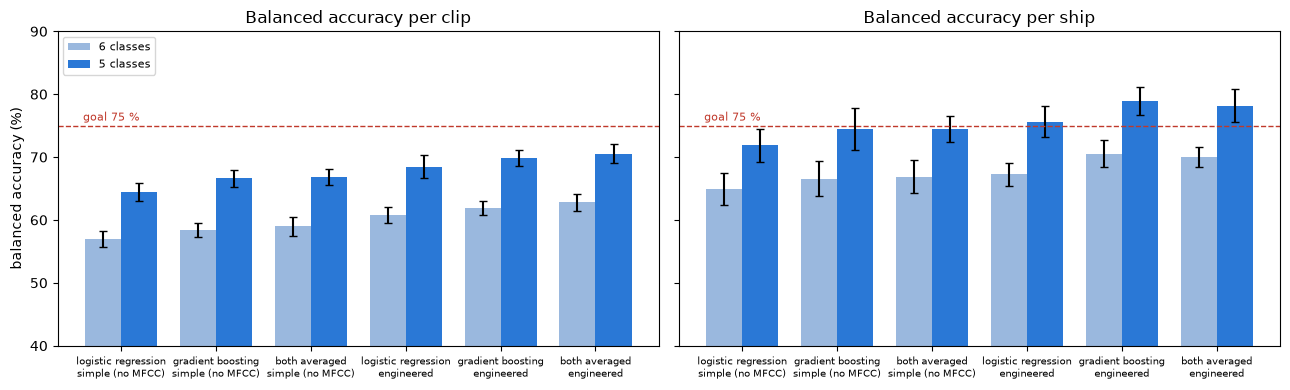

In [6]:
g5 = res.groupby(["features", "model"])[cols].agg(["mean", "std"])
g6 = six_scores.groupby(["features", "model"])[cols].agg(["mean", "std"])
combos = [(f, m) for f in ("simple (no MFCC)", "engineered") for m in (*S.MODELS, F5.BOTH)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
x = np.arange(len(combos))
for j, (col, title) in enumerate(zip(cols, ["per clip", "per ship"])):
    for i, (g, label, color) in enumerate([(g6, "6 classes", "#9ab8de"), (g5, "5 classes", "#2a78d6")]):
        ax[j].bar(x + (i - 0.5) * 0.38, [100 * g.loc[c, (col, "mean")] for c in combos], 0.38,
                  yerr=[100 * g.loc[c, (col, "std")] for c in combos], capsize=3, color=color, label=label)
    ax[j].axhline(75, color="#c0392b", ls="--", lw=1); ax[j].text(-0.4, 75.8, "goal 75 %", color="#c0392b", fontsize=8)
    ax[j].set_xticks(x, [f"{m}\n{f}" for f, m in combos], fontsize=7)
    ax[j].set_title(f"Balanced accuracy {title}"); ax[j].set_ylim(40, 90)
ax[0].set_ylabel("balanced accuracy (%)"); ax[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Five classes, one answer per ship, reach the 75 % goal; per clip they don't.**

- **Engineered features + gradient boosting:** 69.9 ± 1.3 % per clip and **78.9 ± 2.2 % per ship**, against 61.9
  and 70.5 % with six classes. Every one of the five folds is above 75 % per ship (76.4-82.5 %).
- Averaging both models gives 70.5 % per clip (the best per clip) and 78.2 % per ship. Logistic regression alone
  reaches 75.6 % per ship; even the simple features with gradient boosting come close (74.4 %).
- **Training on five classes gives the same result as adding the six-class model's cargo and tanker answers
  afterwards** (69.9 against 69.8 %; 78.9 against 79.0 %). The six-class model already put its doubt between
  these two classes; merging just stops counting that doubt as an error. The gain comes from the question asked,
  not from a better model.
- **Per clip, 75 % is not reached:** at best 70.5 %. One 5-second clip of a small boat is often ambiguous.

## 4. What is still wrong

Recall per class (engineered features, gradient boosting), per clip and per ship. For the merged class, the cargo
ships and the tankers are also shown separately.

                   per clip  per ship
background             85.3      92.4
cargo + tanker         96.3      96.2
fishing                42.9      52.1
pleasurecraft          63.1      73.9
tug                    61.6      79.8
  of which cargo       96.1      95.9
  of which tanker      96.5      98.7


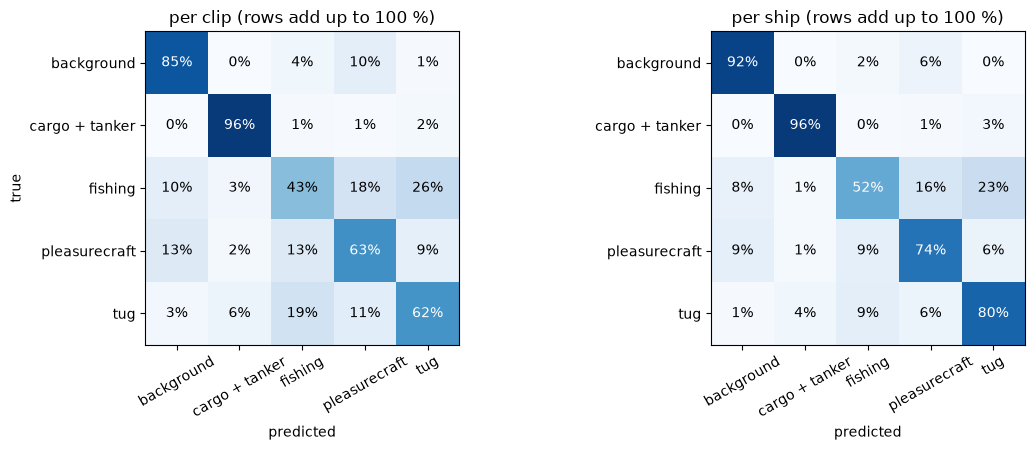

In [7]:
p5 = preds[(preds.features == BEST[0]) & (preds.model == BEST[1])].copy()
p5["called"] = p5[P5].to_numpy().argmax(1)
ship5 = p5.groupby(["fold", "ship"]).agg(**{c: (c, "mean") for c in P5}, y=("y", "first"), y6=("y6", "first"),
                                          clips=("y", "size"))
ship5["called"] = ship5[P5].to_numpy().argmax(1)


def recall_by(df, key, names):
    return pd.Series({names[i]: (d.called == d.y).mean() for i, d in df.groupby(key)})


rec = pd.DataFrame({"per clip": recall_by(p5, "y", F5.CLASSES5), "per ship": recall_by(ship5, "y", F5.CLASSES5)})
for name in ("cargo", "tanker"):
    i = S.CLASSES6.index(name)
    rec.loc[f"  of which {name}"] = [(p5[p5.y6 == i].called == p5[p5.y6 == i].y).mean(),
                                     (ship5[ship5.y6 == i].called == ship5[ship5.y6 == i].y).mean()]
print((100 * rec).round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (df, title) in zip(ax, [(p5, "per clip"), (ship5, "per ship")]):
    cm = confusion_matrix(df.y, df.called, labels=range(5), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            a.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    a.set_xticks(range(5), F5.CLASSES5, rotation=30); a.set_yticks(range(5), F5.CLASSES5)
    a.set_xlabel("predicted"); a.set_title(f"{title} (rows add up to 100 %)")
ax[0].set_ylabel("true"); plt.tight_layout(); plt.show()

How much does one answer per ship help each class? It depends on how many clips a ship has: the average over many
clips evens out bad moments (a passing noise, the ship far away). Compared within each class, because the classes
differ a lot in clips per ship:

In [8]:
gain = pd.DataFrame({"clips per ship (median)": ship5.groupby("y").clips.median().set_axis(F5.CLASSES5),
                     "per clip (%)": (100 * rec["per clip"].iloc[:5]).round(1),
                     "per ship (%)": (100 * rec["per ship"].iloc[:5]).round(1)})
gain["gain (points)"] = (gain["per ship (%)"] - gain["per clip (%)"]).round(1)
print(gain)

                clips per ship (median)  per clip (%)  per ship (%)  gain (points)
background                          4.0          85.3          92.4            7.1
cargo + tanker                      1.0          96.3          96.2           -0.1
fishing                            15.0          42.9          52.1            9.2
pleasurecraft                       9.0          63.1          73.9           10.8
tug                                12.0          61.6          79.8           18.2


- **The merged class is now almost always right:** 96 % per clip and per ship (cargo ships 96 %, tankers 96-99 %).
- **The remaining errors are among the small boats.** Fishing boats are right only 43 % of the time per clip (52 %
  per ship); they are called tug (26 %) or pleasure craft (18 %). Pleasure craft and background are mixed up
  (10-13 %), probably when the boat is far away and quiet.
- **One answer per ship helps where ships have many clips:** tug +18 points (79.8 % per ship), pleasure craft +11,
  fishing +9, background +7 (4-5 clips per day). The merged class doesn't change: cargo ships have only 1-2 clips,
  and it is already at 96 %.

## 5. What it means

| Balanced accuracy, same test ships | Per clip | Per ship |
|---|---|---|
| 6 classes, engineered + gradient boosting (lesson 13) | 61.9 ± 1.1 % | 70.5 ± 2.2 % |
| **5 classes**, engineered + gradient boosting | 69.9 ± 1.3 % | **78.9 ± 2.2 %** |
| 5 classes, both models averaged | **70.5 ± 1.5 %** | 78.2 ± 2.7 % |

- **75 % is reached per ship, on ships never heard in training**, when cargo and tanker are one class: 78.9 %
  with engineered features and gradient boosting, above 75 % on every fold.
- **The price:** the system no longer tells cargo from tanker. Their sound is almost the same, so that would need
  other information than sound (for example the ship's size or AIS data).
- **Per clip, 75 % is still out of reach** (70.5 % at best). For a decision from one 5-second clip, the weak spot
  is fishing boats against tugs and pleasure craft.
- Merging classes changes the question, so it should be agreed with the professor. The dataset paper's 66.5 %
  (lesson 11, experiment log 4.8) is for a different grouping into five classes, per clip, so it can't be compared
  directly with these numbers.